# PulseSplit — Actual UCI Dataset Experiment

This notebook reads the completed experiment and demonstrates the saved model. It does **not** retrain the model or recompute the held-out test scores.

**Dataset:** [UCI HLS-CMDS](https://archive.ics.uci.edu/dataset/1202/hls-cmds), Torabi, Shirani and Reilly (2025), CC BY 4.0. The dataset folder contains the 435 WAVs in 145 matched triplets used by this experiment.

The supplied outputs are from real data. Scores are SI-SDR in dB, not percentage accuracy. Separately recorded references have unverified time/phase alignment; these results do not establish clinical usefulness.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image, Audio

ROOT = Path.cwd()
if not (ROOT / 'output').is_dir():
    raise FileNotFoundError('Open this notebook from the extracted submission folder')
MODELS = ROOT / 'output' / 'models'
RESULTS = ROOT / 'output' / 'results'
CHARTS = ROOT / 'output' / 'charts'
sys.path.insert(0, str(MODELS / 'source'))
sys.dont_write_bytecode = True
torch.set_num_threads(4)
print('Submission:', ROOT.name)
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)


Submission: PulseSplit_Submission
Python: 3.14.2
PyTorch: 2.14.1+cpu


## 1. Verify the saved model and split

Recordings sharing byte-identical audio are kept in one partition. Related simulator patterns can still occur across partitions.

In [2]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

summary = json.loads((RESULTS / 'summary.json').read_text())
metadata = json.loads((MODELS / 'run_metadata.json').read_text())
split = json.loads((MODELS / 'split.json').read_text())
assert sha256(MODELS / 'best.pt') == summary['checkpoint_sha256']
assert sha256(MODELS / 'split.json') == summary['split_sha256']
seen = set()
hash_partitions = {}
for partition in ['train', 'val', 'test']:
    ids = split[partition]
    assert not seen.intersection(ids)
    seen.update(ids)
    for key in ids:
        for digest in split['file_hashes'][key].values():
            assert hash_partitions.get(digest, partition) == partition
            hash_partitions[digest] = partition
print('Verified model and split hashes; no identical audio crosses partitions.')
display(pd.DataFrame([{'Partition': name, 'Recordings': len(split[name]),
                       'Source groups': sum(v == name for v in split['group_assignments'].values())}
                      for name in ['train', 'val', 'test']]))
display(pd.DataFrame([{'Epochs completed': metadata['epochs_completed'],
                       'Selected epoch': metadata['selected_epoch'],
                       'Parameters': metadata['parameter_count'],
                       'Validation log-magnitude MAE': metadata['best_val_logmag_mae'],
                       'Training seconds': metadata['runtime_seconds']}]))


Verified model and split hashes; no identical audio crosses partitions.


,Partition,Recordings,Source groups
0,train,101,14
1,val,22,5
2,test,22,9


,Epochs completed,Selected epoch,Parameters,Validation log-magnitude MAE,Training seconds
0,10,3,488434,0.079926,428.097408


## 2. Measured held-out results

The following numbers come directly from the saved 22-recording evaluation. Positive gain means a higher score than using the mixture as the prediction. Both descriptive gain intervals include zero. Recording bootstrap intervals do not account for dependence within source groups.

In [3]:
rows = []
for source in ['heart', 'lung']:
    gain = summary['statistics'][f'{source}_improvement']
    rows.append({'Source': source.title(),
                 'Mixture SI-SDR (dB)': summary['metrics'][f'{source}_baseline_si_sdr'],
                 'Estimate SI-SDR (dB)': summary['metrics'][f'{source}_si_sdr'],
                 'Mean gain (dB)': gain['mean'],
                 'Descriptive gain CI': gain['mean_ci95']})
display(pd.DataFrame(rows).round(3))
per_recording = pd.read_csv(RESULTS / 'test_per_recording.csv', dtype={'id': str})
assert set(per_recording['id']) == set(split['test'])
assert len(per_recording) == summary['num_test_recordings']
display(per_recording.round(3))


,Source,Mixture SI-SDR (dB),Estimate SI-SDR (dB),Mean gain (dB),Descriptive gain CI
0,Heart,-28.201,-25.010,3.191,"[-0.03363132413422376, 6.5040666131988605]"
1,Lung,-27.069,-26.909,0.160,"[-1.2678980476996653, 2.4236565021699183]"


,id,heart_si_sdr,lung_si_sdr,heart_baseline_si_sdr,lung_baseline_si_sdr,heart_improvement,lung_improvement
0,0007,-39.241,-40.206,-56.559,-38.051,17.318,-2.156
1,0008,-29.694,-40.983,-34.418,-39.199,4.724,-1.784
2,0011,-35.011,-27.180,-31.778,-27.588,-3.233,0.407
3,0027,-30.783,-42.412,-33.403,-39.870,2.621,-2.542
4,0035,-35.111,-28.373,-51.575,-26.577,16.464,-1.795
5,0039,-33.853,-55.546,-35.665,-76.419,1.812,20.873
6,0048,-37.019,-39.526,-35.047,-40.352,-1.972,0.826
7,0061,-33.526,-40.761,-33.861,-38.274,0.335,-2.487
8,0064,-38.559,-30.770,-31.799,-30.555,-6.760,-0.215
9,0065,-32.910,-44.863,-47.525,-41.538,14.615,-3.326


## 3. Training and evaluation charts

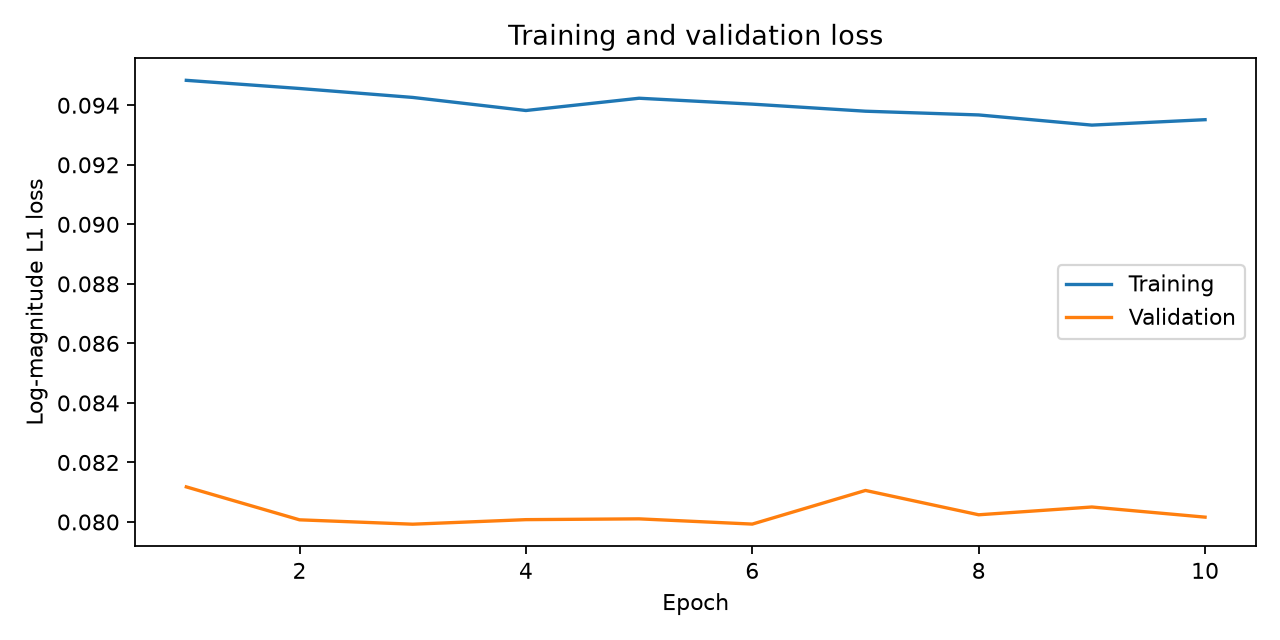

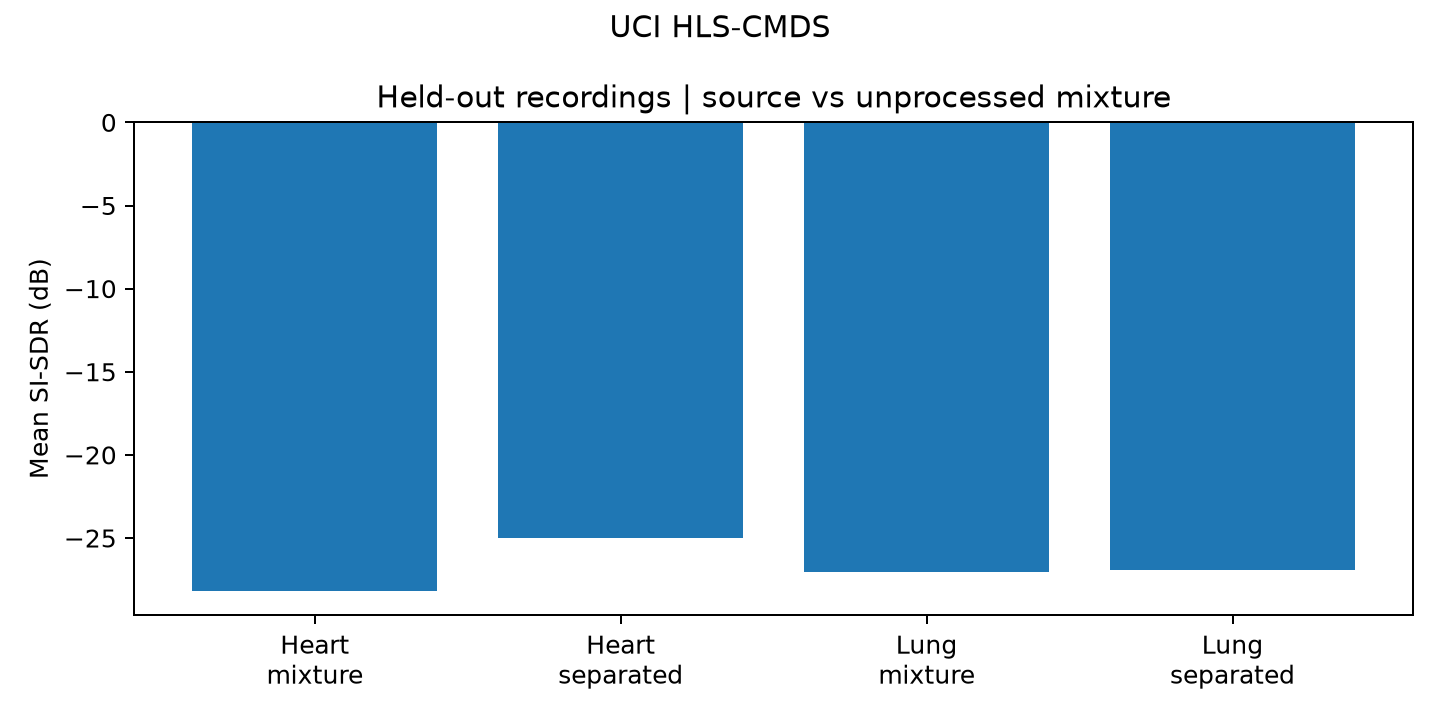

In [4]:
display(Image(filename=str(CHARTS / 'training_history.png')))
display(Image(filename=str(CHARTS / 'test_comparison.png')))


## 4. Dataset inspection

The downloaded matched WAVs are mono, 4,000 Hz, and 15 seconds. This differs from the catalogue description of 22,050 Hz. Processing at 8,000 Hz adds no original recorded bandwidth. Near-full-scale samples are flagged as possible clipping, not proven distortion.

In [5]:
audit = json.loads((RESULTS / 'audit' / 'dataset_audit.json').read_text())
print('Matched triplets:', audit['recording_count'])
print('Matched WAVs:', audit['file_count'])
print('Native sample rates:', audit['sample_rates'])
print('Audit status:', audit['status'])
print('Warnings:', audit['issue_counts'])
index = pd.read_csv(ROOT / 'dataset' / 'recordings.csv', dtype={'id': str})
assert set(index['id']) == seen
print('Dataset index verified:', len(index), 'matched triplets')
display(index.head())


Matched triplets: 145
Matched WAVs: 435
Native sample rates: [4000]
Audit status: warnings
Warnings: {'possible_clipping': 36}
Dataset index verified: 145 matched triplets


,id,mixed,heart,lung,partition
0,0001,mixed/M0001.wav,heart/H0001.wav,lung/L0001.wav,train
1,0002,mixed/M0002.wav,heart/H0002.wav,lung/L0002.wav,train
2,0003,mixed/M0003.wav,heart/H0003.wav,lung/L0003.wav,train
3,0004,mixed/M0004.wav,heart/H0004.wav,lung/L0004.wav,val
4,0005,mixed/M0005.wav,heart/H0005.wav,lung/L0005.wav,train


## 5. Listen to a validation recording

This example uses a validation recording, rather than selecting a test example by its score. Outputs are estimates from the actual trained model. Playback keeps the shared normalization and does not provide a new quality score.

In [6]:
from pulsesplit.audio import load_audio
from pulsesplit.pipeline import load_checkpoint, separate_signal

model, settings = load_checkpoint(MODELS / 'best.pt')
example_id = split['val'][0]
example_path = ROOT / 'dataset' / 'mixed' / f'M{example_id}.wav'
mix = load_audio(example_path, settings['sample_rate'])
mix = mix / max(float(np.max(np.abs(mix))), 1e-6)
predicted = separate_signal(model, mix, sample_rate=settings['sample_rate'],
                            seconds=settings['seconds'])
assert predicted.shape == (2, len(mix)) and np.isfinite(predicted).all()
print('Validation recording:', example_id)
for label, signal in [('Mixture', mix), ('Estimated heart', predicted[0]), ('Estimated lung', predicted[1])]:
    print(label)
    display(Audio(signal, rate=settings['sample_rate'], normalize=False))


Validation recording: 0004
Mixture


Estimated heart


Estimated lung


## Files to read

- `output/results/Actual_Experiment_Report.docx`: editable report with measured results and limitations.
- `output/results/test_per_recording.csv`: all held-out scores.
- `output/models/best.pt`: selected trained checkpoint.
- `output/models/split.json`: partition IDs, audio hashes, and source groups.
- `output/charts/`: training and evaluation graphs.

The original synthetic software checks are separate from this actual-data submission.